# Data walkthrough: from the raw files to the 26 features

Ahsan Ahmed (26K-7808), CY-5002 course project

This notebook shows what the two datasets look like when downloaded and what is done to them before training. It does not have its own copy of the cleaning code. Every step calls the functions in `src/prepare_data.py`, which is the script used for the experiments.

Contents

1. Bot-IoT (5% subset) as downloaded
2. UNSW-NB15 as downloaded
3. Class counts and imbalance
4. Where each of the 26 features comes from
5. Cleaning steps: ports, protocol, window statistics, IP addresses
6. Check against the saved files
7. The shape the LSTM receives

In [1]:
import glob, os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.join("..", "src"))
import prepare_data as prep
from prepare_data import FEATURES, PROTO_NUMBER, WINDOW

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
print(len(FEATURES), "features in the common set")

26 features in the common set


## 1. Bot-IoT (5% subset) as downloaded

Four CSV files with a header row. The first few rows of the first file, unchanged:

In [2]:
bot_files = sorted(glob.glob(os.path.join(prep.RAW_BOT, "UNSW_2018_IoT_Botnet_Full5pc_?.csv")))
raw_bot = pd.read_csv(bot_files[0], nrows=5)
print([os.path.basename(f) for f in bot_files])
print(raw_bot.shape[1], "columns")
raw_bot

['UNSW_2018_IoT_Botnet_Full5pc_1.csv', 'UNSW_2018_IoT_Botnet_Full5pc_2.csv', 'UNSW_2018_IoT_Botnet_Full5pc_3.csv', 'UNSW_2018_IoT_Botnet_Full5pc_4.csv']
46 columns


,pkSeqID,stime,flgs,flgs_number,proto,proto_number,saddr,sport,daddr,dport,pkts,bytes,state,state_number,ltime,seq,dur,mean,stddev,sum,min,max,spkts,dpkts,sbytes,dbytes,rate,srate,drate,TnBPSrcIP,TnBPDstIP,TnP_PSrcIP,TnP_PDstIP,TnP_PerProto,TnP_Per_Dport,AR_P_Proto_P_SrcIP,AR_P_Proto_P_DstIP,N_IN_Conn_P_DstIP,N_IN_Conn_P_SrcIP,AR_P_Proto_P_Sport,AR_P_Proto_P_Dport,Pkts_P_State_P_Protocol_P_DestIP,Pkts_P_State_P_Protocol_P_SrcIP,attack,category,subcategory
0,1,1.528089e+09,e,1,tcp,1,192.168.100.147,49960,192.168.100.7,80,8,1980,RST,1,1.528089e+09,9,7.056393,0.068909,0.068909,0.137818,0.000000,0.137818,5,3,650,1330,0.992008,0.566862,14.511893,157426,201841,602,770,772,772,1.142970,1.12704,96,75,1.133720,1.129970,770,602,1,DoS,HTTP
1,2,1.528089e+09,e,1,arp,2,192.168.100.7,-1,192.168.100.147,-1,2,120,CON,2,1.528089e+09,10,0.000131,0.000131,0.000000,0.000131,0.000131,0.000131,1,1,60,60,7633.588379,0.000000,0.000000,360,120,6,2,8,8,0.003857,15267.20000,1,2,0.005142,0.005142,2,6,1,DoS,HTTP
2,3,1.528089e+09,e,1,tcp,1,192.168.100.147,49962,192.168.100.7,80,8,2126,RST,1,1.528089e+09,11,7.047852,0.064494,0.064494,0.128988,0.000000,0.128988,5,3,796,1330,0.993210,0.567549,15.505319,157426,201841,602,770,772,772,1.142970,1.12704,96,75,1.135100,1.129970,770,602,1,DoS,HTTP
3,4,1.528089e+09,e,1,tcp,1,192.168.100.147,49964,192.168.100.7,80,8,2024,RST,1,1.528089e+09,12,7.047592,0.064189,0.064189,0.128378,0.000000,0.128378,5,3,694,1330,0.993247,0.567570,15.578993,157426,201841,602,770,772,772,1.142970,1.12704,96,75,1.135140,1.129970,770,602,1,DoS,HTTP
4,5,1.528089e+09,e,1,tcp,1,192.168.100.147,49966,192.168.100.7,80,8,2319,RST,1,1.528089e+09,13,7.046841,0.063887,0.063887,0.127774,0.000000,0.127774,5,3,989,1330,0.993353,0.567630,15.652637,157426,201841,602,770,772,772,1.142970,1.12704,96,75,1.135260,1.129970,770,602,1,DoS,HTTP


In [3]:
bot = prep.load_botiot()      # reads the four files, fixes ports, sorts by pkSeqID
print("rows:", f"{len(bot):,}", " columns:", bot.shape[1])
print("missing values in the whole table:", int(bot.isna().sum().sum()))
bot.groupby(["category", "subcategory"]).size().rename("records").to_frame()

rows: 3,668,522  columns: 46
missing values in the whole table: 0


records
category       subcategory               
DDoS           HTTP                   989
               TCP                 977380
               UDP                 948255
DoS            HTTP                  1485
               TCP                 615800
               UDP                1032975
Normal         Normal                 477
Reconnaissance OS_Fingerprint       17914
               Service_Scan         73168
Theft          Data_Exfiltration        6
               Keylogging              73

## 2. UNSW-NB15 as downloaded

Four CSV files without a header row. The column names are in a separate file, `NUSW-NB15_features.csv`. The label column `attack_cat` is empty for normal traffic.

In [4]:
names = pd.read_csv(os.path.join(prep.RAW_UNSW, "NUSW-NB15_features.csv"),
                    encoding="latin-1")["Name"].str.strip().tolist()
unsw_files = sorted(glob.glob(os.path.join(prep.RAW_UNSW, "UNSW-NB15_?.csv")))
raw_unsw = pd.read_csv(unsw_files[0], header=None, names=names, nrows=5)
print(len(names), "columns")
raw_unsw

49 columns


,srcip,sport,dstip,dsport,proto,state,dur,sbytes,dbytes,sttl,dttl,sloss,dloss,service,Sload,Dload,Spkts,Dpkts,swin,dwin,stcpb,dtcpb,smeansz,dmeansz,trans_depth,res_bdy_len,Sjit,Djit,Stime,Ltime,Sintpkt,Dintpkt,tcprtt,synack,ackdat,is_sm_ips_ports,ct_state_ttl,ct_flw_http_mthd,is_ftp_login,ct_ftp_cmd,ct_srv_src,ct_srv_dst,ct_dst_ltm,ct_src_ ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,attack_cat,Label
0,59.166.0.0,1390,149.171.126.6,53,udp,CON,0.001055,132,164,31,29,0,0,dns,500473.93750,621800.93750,2,2,0,0,0,0,66,82,0,0,0.00000,0.000000,1421927414,1421927414,0.017,0.013000,0,0,0,0,0,0,0,0,3,7,1,3,1,1,1,NaN,0
1,59.166.0.0,33661,149.171.126.9,1024,udp,CON,0.036133,528,304,31,29,0,0,-,87676.08594,50480.17188,4,4,0,0,0,0,132,76,0,0,9.89101,10.682733,1421927414,1421927414,7.005,7.564333,0,0,0,0,0,0,0,0,2,4,2,3,1,1,2,NaN,0
2,59.166.0.6,1464,149.171.126.7,53,udp,CON,0.001119,146,178,31,29,0,0,dns,521894.53130,636282.37500,2,2,0,0,0,0,73,89,0,0,0.00000,0.000000,1421927414,1421927414,0.017,0.013000,0,0,0,0,0,0,0,0,12,8,1,2,2,1,1,NaN,0
3,59.166.0.5,3593,149.171.126.5,53,udp,CON,0.001209,132,164,31,29,0,0,dns,436724.56250,542597.18750,2,2,0,0,0,0,66,82,0,0,0.00000,0.000000,1421927414,1421927414,0.043,0.014000,0,0,0,0,0,0,0,0,6,9,1,1,1,1,1,NaN,0
4,59.166.0.3,49664,149.171.126.0,53,udp,CON,0.001169,146,178,31,29,0,0,dns,499572.25000,609067.56250,2,2,0,0,0,0,73,89,0,0,0.00000,0.000000,1421927414,1421927414,0.005,0.003000,0,0,0,0,0,0,0,0,7,9,1,1,1,1,1,NaN,0


In [5]:
unsw = prep.load_unsw()       # keeps the columns we need, renames them, sorts by start time
print("rows:", f"{len(unsw):,}", " columns kept:", unsw.shape[1])
unsw.head()

rows: 2,540,047  columns kept: 15


,stime,ltime,saddr,daddr,dur,sport,dport,spkts,dpkts,sbytes,dbytes,pkts,bytes,proto,category
0,1.421927e+09,1.421927e+09,10.40.182.1,224.0.0.5,50.004337,0,0,6,0,384,0,6,384,ospf,Normal
1,1.421927e+09,1.421927e+09,10.40.85.1,224.0.0.5,50.004341,0,0,6,0,384,0,6,384,ospf,Normal
2,1.421927e+09,1.421927e+09,10.40.182.1,224.0.0.5,50.004337,0,0,6,0,384,0,6,384,ospf,Normal
3,1.421927e+09,1.421927e+09,10.40.85.1,224.0.0.5,50.004341,0,0,6,0,384,0,6,384,ospf,Normal
4,1.421927e+09,1.421927e+09,192.168.241.243,192.168.241.243,0.000000,259,49320,5,0,1780,0,5,1780,icmp,Normal


## 3. Class counts and imbalance

UNSW-NB15 is mostly normal traffic. Bot-IoT is almost entirely attack traffic. The chart uses a log scale, otherwise the small classes would not be visible.

In [6]:
counts = pd.DataFrame({"UNSW-NB15": unsw["category"].value_counts(),
                       "Bot-IoT 5%": bot["category"].value_counts()}).fillna(0).astype(int)
counts = counts.sort_values(["Bot-IoT 5%", "UNSW-NB15"], ascending=False)
share = (counts / counts.sum() * 100).round(3).add_suffix(" (%)")
pd.concat([counts, share], axis=1)

,UNSW-NB15,Bot-IoT 5%,UNSW-NB15 (%),Bot-IoT 5% (%)
category,,,,
DDoS,0,1926624,0.000,52.518
DoS,16353,1650260,0.644,44.984
Reconnaissance,13987,91082,0.551,2.483
Normal,2218764,477,87.351,0.013
Theft,0,79,0.000,0.002
Generic,215481,0,8.483,0.000
Exploits,44525,0,1.753,0.000
Fuzzers,24246,0,0.955,0.000
Analysis,2677,0,0.105,0.000


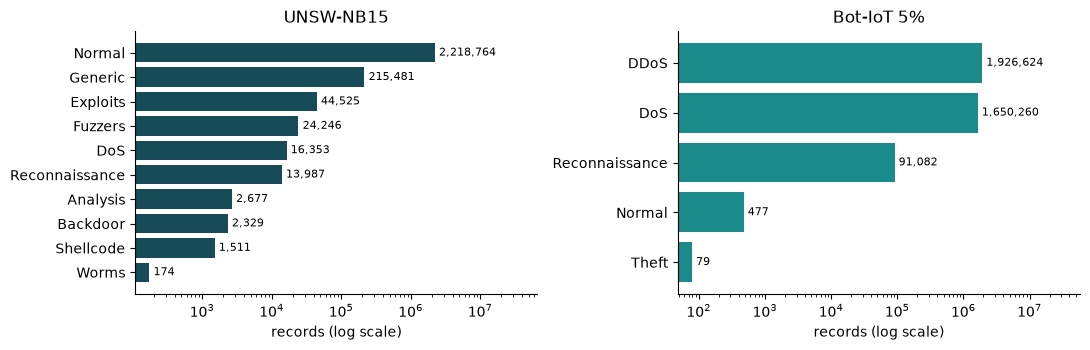

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, col, colour in zip(axes, counts.columns, ["#164B57", "#1B8A8A"]):
    c = counts[col][counts[col] > 0].sort_values()
    ax.barh(c.index, c.values, color=colour)
    ax.set_xscale("log")
    ax.set_title(col)
    ax.set_xlabel("records (log scale)")
    for y, v in enumerate(c.values):
        ax.text(v * 1.15, y, f"{v:,}", va="center", fontsize=8)
    ax.set_xlim(right=c.max() * 30)
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

Classes present in both datasets. Only these can be used for the cross-dataset test in the extension. UNSW-NB15 has no DDoS and no Theft class.

In [8]:
counts[(counts > 0).all(axis=1)]

,UNSW-NB15,Bot-IoT 5%
category,,
DoS,16353,1650260
Reconnaissance,13987,91082
Normal,2218764,477


## 4. Where each of the 26 features comes from

Bot-IoT already has all 26 columns. UNSW-NB15 has 11 of them under other names, 3 follow from simple arithmetic or a lookup, and 12 are statistics over windows of 100 connections that have to be computed.

In [9]:
direct = {"stime": "Stime", "ltime": "Ltime", "saddr": "srcip", "daddr": "dstip", "dur": "dur",
          "sport": "sport", "dport": "dsport", "spkts": "Spkts", "dpkts": "Dpkts",
          "sbytes": "sbytes", "dbytes": "dbytes"}
derived = {"pkts": "Spkts + Dpkts", "bytes": "sbytes + dbytes", "proto_number": "lookup on proto"}
rows = []
for i, f in enumerate(FEATURES, 1):
    if f in direct:
        how, src = "renamed", direct[f]
    elif f in derived:
        how, src = "derived", derived[f]
    else:
        how, src = "computed", f"window of {WINDOW} connections"
    rows.append({"#": i, "feature": f, "cluster": "flow" if i <= 9 else "TCP",
                 "in Bot-IoT file": f in bot.columns, "UNSW-NB15": how, "UNSW-NB15 source": src})
table = pd.DataFrame(rows).set_index("#")
print(table["UNSW-NB15"].value_counts().to_string())
table

UNSW-NB15
computed    12
renamed     11
derived      3


,feature,cluster,in Bot-IoT file,UNSW-NB15,UNSW-NB15 source
#,,,,,
1,stime,flow,True,renamed,Stime
2,ltime,flow,True,renamed,Ltime
3,saddr,flow,True,renamed,srcip
4,daddr,flow,True,renamed,dstip
5,dur,flow,True,renamed,dur
6,AR_P_Proto_P_SrcIP,flow,True,computed,window of 100 connections
7,AR_P_Proto_P_DstIP,flow,True,computed,window of 100 connections
8,N_IN_Conn_P_SrcIP,flow,True,computed,window of 100 connections
9,N_IN_Conn_P_DstIP,flow,True,computed,window of 100 connections


## 5. Cleaning steps

### 5.1 Ports

Port columns are not clean integers in the raw files. Bot-IoT writes some values in hex, and the count below equals its number of ICMP records. UNSW-NB15 has a few hex values and uses `-` when a record has no port. `port_to_int` converts hex to an integer and uses -1 when there is no port, which is what the Bot-IoT 5% files already do for ARP.

In [10]:
def odd_ports(series):
    s = series.astype(str).str.strip()
    return s[pd.to_numeric(s, errors="coerce").isna()]

raw_ports_bot = pd.concat([pd.read_csv(f, usecols=["sport", "dport"], dtype=str) for f in bot_files])
raw_ports_unsw = pd.concat([pd.read_csv(f, header=None, names=names, usecols=["sport", "dsport"], dtype=str)
                            for f in unsw_files])
for label, s in [("Bot-IoT sport", raw_ports_bot["sport"]), ("Bot-IoT dport", raw_ports_bot["dport"]),
                 ("UNSW-NB15 sport", raw_ports_unsw["sport"]), ("UNSW-NB15 dsport", raw_ports_unsw["dsport"])]:
    odd = odd_ports(s)
    print(f"{label:17s} non-decimal values: {len(odd):>7,}   examples: {odd.value_counts().head(4).index.tolist()}")

Bot-IoT sport     non-decimal values:   9,052   examples: ['0x0303', '0x0008', '0x000d', '0x0011']


Bot-IoT dport     non-decimal values:   9,052   examples: ['0x5000', '0x0000', '0xfeff', '0x6a51']


UNSW-NB15 sport   non-decimal values:       8   examples: ['0x000c', '0x000b', '-']


UNSW-NB15 dsport  non-decimal values:     304   examples: ['0xcc09', '0xc0a8', '-', '0x20205321']


In [11]:
sample = pd.Series(["80", "0x0303", "-", "53", "0xc0a8"])
pd.DataFrame({"raw": sample, "after port_to_int": prep.port_to_int(sample)})

,raw,after port_to_int
0,80,80
1,0x0303,771
2,-,-1
3,53,53
4,0xc0a8,49320


### 5.2 Protocol name to number

Bot-IoT numbers its five protocols 1 to 5. UNSW-NB15 contains many more protocol names, so each extra one gets the next free integer. One table is used for both datasets.

In [12]:
proto_map = dict(PROTO_NUMBER)
for p in sorted(set(unsw["proto"]) | set(bot["proto"])):
    if p not in proto_map:
        proto_map[p] = len(proto_map) + 1
unsw["proto_number"] = unsw["proto"].map(proto_map).astype("int64")
bot["proto_number"] = bot["proto"].map(proto_map).astype("int64")

print("protocols in Bot-IoT:  ", bot["proto"].nunique())
print("protocols in UNSW-NB15:", unsw["proto"].nunique())
print("size of the shared table:", len(proto_map))
pd.DataFrame({"Bot-IoT records": bot["proto"].value_counts(),
              "UNSW-NB15 records": unsw["proto"].value_counts()}).loc[list(PROTO_NUMBER)].fillna(0).astype(int).assign(
              number=lambda d: [proto_map[p] for p in d.index])

protocols in Bot-IoT:   5
protocols in UNSW-NB15: 135
size of the shared table: 136


,Bot-IoT records,UNSW-NB15 records,number
proto,,,
tcp,1662812,1495074,1
arp,213,10064,2
udp,1996437,990435,3
icmp,9052,524,4
ipv6-icmp,8,0,5


### 5.3 Window statistics for UNSW-NB15

Bot-IoT describes each connection together with its neighbours, for example the total bytes sent by the same source IP within the same 100 connections. UNSW-NB15 has no such columns, so `add_window_features` computes them. Records are sorted by start time and cut into consecutive windows of 100.

The small example below is the first window. Rows with the same source address share the same `TnBPSrcIP` (sum of `bytes`) and `N_IN_Conn_P_SrcIP` (number of rows).

In [13]:
first = prep.add_window_features(unsw.head(WINDOW).copy())
cols = ["saddr", "proto", "pkts", "bytes", "dur", "TnBPSrcIP", "TnP_PSrcIP", "N_IN_Conn_P_SrcIP", "AR_P_Proto_P_SrcIP"]
first.sort_values("saddr")[cols].head(12)

,saddr,proto,pkts,bytes,dur,TnBPSrcIP,TnP_PSrcIP,N_IN_Conn_P_SrcIP,AR_P_Proto_P_SrcIP
27,10.40.170.2,arp,1,46,0.000000,92,2,2,0.000000
28,10.40.170.2,arp,1,46,0.000000,92,2,2,0.000000
0,10.40.182.1,ospf,6,384,50.004337,1064,20,4,0.119990
2,10.40.182.1,ospf,6,384,50.004337,1064,20,4,0.119990
18,10.40.182.1,arp,4,148,31.328632,1064,20,4,0.127679
19,10.40.182.1,arp,4,148,31.328632,1064,20,4,0.127679
24,10.40.182.3,arp,1,46,0.000000,92,2,2,0.000000
29,10.40.182.3,arp,1,46,0.000000,92,2,2,0.000000
1,10.40.85.1,ospf,6,384,50.004341,768,12,2,0.119990
3,10.40.85.1,ospf,6,384,50.004341,768,12,2,0.119990


In [14]:
check = first.groupby("saddr").agg(rows=("bytes", "size"), bytes_sum=("bytes", "sum"),
                                   TnBPSrcIP=("TnBPSrcIP", "first"), N_IN_Conn_P_SrcIP=("N_IN_Conn_P_SrcIP", "first"))
check

,rows,bytes_sum,TnBPSrcIP,N_IN_Conn_P_SrcIP
saddr,,,,
10.40.170.2,2,92,92,2
10.40.182.1,4,1064,1064,4
10.40.182.3,2,92,92,2
10.40.85.1,2,768,768,2
10.40.85.30,2,444,444,2
175.45.176.0,1,1630,1630,1
175.45.176.2,3,36018,36018,3
175.45.176.3,1,728,728,1
192.168.241.243,2,3560,3560,2


In [15]:
unsw = prep.add_window_features(unsw)     # all 2.54M records
new_cols = [f for f in FEATURES if f not in direct and f not in derived]
print(len(new_cols), "columns added")
unsw[new_cols].describe().T[["min", "50%", "max"]]

12 columns added


,min,50%,max
AR_P_Proto_P_SrcIP,0.0,625.185799,5.060986e+06
AR_P_Proto_P_DstIP,0.0,600.829257,2.000000e+06
N_IN_Conn_P_SrcIP,1.0,12.000000,9.900000e+01
N_IN_Conn_P_DstIP,1.0,11.000000,9.900000e+01
TnBPSrcIP,46.0,146642.000000,1.155016e+08
TnBPDstIP,46.0,135440.000000,1.157235e+08
TnP_PSrcIP,1.0,510.000000,1.349740e+05
TnP_PDstIP,1.0,470.000000,1.354760e+05
TnP_PerProto,1.0,4552.000000,1.509000e+05
TnP_Per_Dport,1.0,118.000000,1.506040e+05


### 5.4 IP addresses to integers

The paper replaces every IP address by a random unique integer. The same table is used for both datasets and the random generator has a fixed seed, so the mapping is the same on every run.

In [16]:
ips = sorted(set(unsw["saddr"]) | set(unsw["daddr"]) | set(bot["saddr"]) | set(bot["daddr"]))
rng = np.random.default_rng(42)
ip_map = dict(zip(ips, rng.permutation(len(ips)) + 1))
print("unique IP addresses in both datasets:", len(ips))
example = pd.DataFrame({"address": bot["saddr"].value_counts().head(5).index})
example["integer"] = example["address"].map(ip_map)
example["Bot-IoT records as source"] = bot["saddr"].value_counts().head(5).values
for d in (unsw, bot):
    d["saddr"] = d["saddr"].map(ip_map).astype("int64")
    d["daddr"] = d["daddr"].map(ip_map).astype("int64")
example

unique IP addresses in both datasets: 142


,address,integer,Bot-IoT records as source
0,192.168.100.147,69,950966
1,192.168.100.148,8,923290
2,192.168.100.150,53,890262
3,192.168.100.149,19,890146
4,192.168.100.3,39,8281


## 6. Check against the saved files

`python src/prepare_data.py` writes two parquet files that the experiments read. The tables built in this notebook should be identical to them.

In [17]:
saved_unsw = pd.read_parquet(os.path.join(prep.OUT, "unsw_26.parquet"))
saved_bot = pd.read_parquet(os.path.join(prep.OUT, "botiot_26.parquet"))
for label, here, saved in [("UNSW-NB15", unsw, saved_unsw), ("Bot-IoT 5%", bot, saved_bot)]:
    same = np.array_equal(here[FEATURES].to_numpy(dtype="float64"), saved[FEATURES].to_numpy(dtype="float64"))
    print(f"{label:11s} shape {saved.shape}  missing values {int(saved[FEATURES].isna().sum().sum())}  "
          f"identical to this notebook: {same}")

UNSW-NB15   shape (2540047, 28)  missing values 0  identical to this notebook: True


Bot-IoT 5%  shape (3668522, 28)  missing values 0  identical to this notebook: True


In [18]:
saved_bot[FEATURES + ["category"]].head()

,stime,ltime,saddr,daddr,dur,AR_P_Proto_P_SrcIP,AR_P_Proto_P_DstIP,N_IN_Conn_P_SrcIP,N_IN_Conn_P_DstIP,sport,dport,pkts,bytes,proto_number,spkts,dpkts,sbytes,dbytes,TnBPSrcIP,TnBPDstIP,TnP_PSrcIP,TnP_PDstIP,TnP_PerProto,TnP_Per_Dport,AR_P_Proto_P_Sport,AR_P_Proto_P_Dport,category
0,1.528089e+09,1.528089e+09,69,110,7.056393,1.142970,1.12704,75,96,49960,80,8,1980,1,5,3,650,1330,157426,201841,602,770,772,772,1.133720,1.129970,DoS
1,1.528089e+09,1.528089e+09,110,69,0.000131,0.003857,15267.20000,2,1,-1,-1,2,120,2,1,1,60,60,360,120,6,2,8,8,0.005142,0.005142,DoS
2,1.528089e+09,1.528089e+09,69,110,7.047852,1.142970,1.12704,75,96,49962,80,8,2126,1,5,3,796,1330,157426,201841,602,770,772,772,1.135100,1.129970,DoS
3,1.528089e+09,1.528089e+09,69,110,7.047592,1.142970,1.12704,75,96,49964,80,8,2024,1,5,3,694,1330,157426,201841,602,770,772,772,1.135140,1.129970,DoS
4,1.528089e+09,1.528089e+09,69,110,7.046841,1.142970,1.12704,75,96,49966,80,8,2319,1,5,3,989,1330,157426,201841,602,770,772,772,1.135260,1.129970,DoS


In [19]:
saved_unsw[FEATURES + ["category"]].head()

,stime,ltime,saddr,daddr,dur,AR_P_Proto_P_SrcIP,AR_P_Proto_P_DstIP,N_IN_Conn_P_SrcIP,N_IN_Conn_P_DstIP,sport,dport,pkts,bytes,proto_number,spkts,dpkts,sbytes,dbytes,TnBPSrcIP,TnBPDstIP,TnP_PSrcIP,TnP_PDstIP,TnP_PerProto,TnP_Per_Dport,AR_P_Proto_P_Sport,AR_P_Proto_P_Dport,category
0,1.421927e+09,1.421927e+09,52,10,50.004337,0.11999,0.11999,4,4,0,0,6,384,83,6,0,384,0,1064,1536,20,24,24,48,0.11999,0.11999,Normal
1,1.421927e+09,1.421927e+09,26,10,50.004341,0.11999,0.11999,2,4,0,0,6,384,83,6,0,384,0,768,1536,12,24,24,48,0.11999,0.11999,Normal
2,1.421927e+09,1.421927e+09,52,10,50.004337,0.11999,0.11999,4,4,0,0,6,384,83,6,0,384,0,1064,1536,20,24,24,48,0.11999,0.11999,Normal
3,1.421927e+09,1.421927e+09,26,10,50.004341,0.11999,0.11999,2,4,0,0,6,384,83,6,0,384,0,768,1536,12,24,24,48,0.11999,0.11999,Normal
4,1.421927e+09,1.421927e+09,22,22,0.000000,0.00000,0.00000,2,2,259,49320,5,1780,4,5,0,1780,0,3560,3560,10,10,10,10,0.00000,0.00000,Normal


In [20]:
both = pd.concat([saved_unsw[FEATURES].agg(["min", "median", "max"]).T.add_prefix("UNSW "),
                  saved_bot[FEATURES].agg(["min", "median", "max"]).T.add_prefix("Bot-IoT ")], axis=1)
both.map(lambda v: f"{v:,.2f}")

,UNSW min,UNSW median,UNSW max,Bot-IoT min,Bot-IoT median,Bot-IoT max
stime,"1,421,927,377.00","1,424,226,977.00","1,424,262,068.00","1,526,344,031.67","1,528,095,723.68","1,529,380,791.14"
ltime,"1,421,927,414.00","1,424,226,978.00","1,424,262,069.00","1,526,344,227.08","1,528,095,729.96","1,529,381,808.19"
saddr,1.00,68.00,142.00,8.00,53.00,119.00
daddr,1.00,79.00,142.00,2.00,39.00,141.00
dur,0.00,0.02,"8,786.64",0.00,15.51,"2,771.49"
AR_P_Proto_P_SrcIP,0.00,625.19,"5,060,985.80",0.00,0.39,"2,714,290.00"
AR_P_Proto_P_DstIP,0.00,600.83,"2,000,000.00",0.00,0.40,"1,000,000.00"
N_IN_Conn_P_SrcIP,1.00,12.00,99.00,1.00,100.00,100.00
N_IN_Conn_P_DstIP,1.00,11.00,99.00,1.00,100.00,100.00
sport,-1.00,"31,687.00","65,535.00",-1.00,"33,329.00","65,535.00"


## 7. The shape the LSTM receives

The reproduction does not train on single records. Following the paper, 128 consecutive records of one class form one training example with one label. Values are log scaled and standardised with the statistics of the training part. The functions below are imported from `src/reproduce_pbdid.py`.

In [21]:
from reproduce_pbdid import make_groups, scale, GROUP

ddos = make_groups(saved_bot[saved_bot.category == "DDoS"], FEATURES)
normal = make_groups(saved_unsw[saved_unsw.category == "Normal"], FEATURES)
print("DDoS  :", ddos.shape, "= (examples, records per example, features)")
print("Normal:", normal.shape)

x = np.concatenate([ddos[:400], normal[:400]])
x_scaled, _ = scale(x, x[:1])
i = FEATURES.index("bytes")
pd.DataFrame({"raw": x[:, :, i].ravel(), "after log scale and standardising": x_scaled[:, :, i].ravel()}
             ).describe().T[["mean", "std", "min", "max"]].round(2)

DDoS  : (15051, 128, 26) = (examples, records per example, features)
Normal: (17334, 128, 26)


,mean,std,min,max
raw,24102.68,122994.38,28.0,1679682.00
after log scale and standardising,0.00,1.00,-2.0,3.56
